### Setup

These cells are copied unchanged from Section 1 of `exam2.ipynb`: the imports, the Black–Scholes functions and sample data of §1.4, and the simulation code of §1.6–§1.8. Run them before the Results below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.integrate import quad
from scipy.stats import binom


In [2]:
def _d1_d2(S, K, T, r, sigma):
    # d1 and d2 as in §1.4 (Lecture 1, p.43). np.log / np.sqrt rather than math.*, so that
    # S, sigma, T and r may be arrays when the data are varied in the parameter studies.
    sqrtT = np.sqrt(T)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * sqrtT)
    return d1, d1 - sigma * sqrtT


def bs_price(S, K, T, r, sigma, kind='call'):
    '''
    S: spot price
    K: strike price
    T: time to expiry T - t (in years)
    r: risk-free interest rate (annualized)
    sigma: volatility (annualized)
    kind: 'call' or 'put'
    '''
    d1, d2 = _d1_d2(S, K, T, r, sigma)
    disc_K = K * np.exp(-r * T)                    # present value of the strike
    if kind == 'call':
        return S * norm.cdf(d1) - disc_K * norm.cdf(d2)
    if kind == 'put':
        return disc_K * norm.cdf(-d2) - S * norm.cdf(-d1)
    raise ValueError(f"kind must be 'call' or 'put', got {kind!r}")


def bs_greeks(S, K, T, r, sigma, kind='call'):
    '''
    Analytic Black-Scholes greeks, the benchmark for the Monte Carlo greeks.
    Returns dict(delta, gamma, vega, theta, rho), each per unit change: vega per 1.00 of sigma,
    rho per 1.00 of r, theta per year. Theta is dV/dt, so it is negative for a call.
    '''
    d1, d2 = _d1_d2(S, K, T, r, sigma)
    sqrtT, disc_K, pdf = np.sqrt(T), K * np.exp(-r * T), norm.pdf(d1)
    gamma = pdf / (S * sigma * sqrtT)              # same for call and put
    vega = S * sqrtT * pdf                         # same for call and put
    decay = -sigma * S * pdf / (2 * sqrtT)         # theta term shared by call and put
    if kind == 'call':
        return dict(delta=norm.cdf(d1), gamma=gamma, vega=vega,
                    theta=decay - r * disc_K * norm.cdf(d2),
                    rho=T * disc_K * norm.cdf(d2))
    if kind == 'put':
        return dict(delta=norm.cdf(d1) - 1, gamma=gamma, vega=vega,
                    theta=decay + r * disc_K * norm.cdf(-d2),
                    rho=-T * disc_K * norm.cdf(-d2))
    raise ValueError(f"kind must be 'call' or 'put', got {kind!r}")


def payoff(ST, K, kind='call'):
    # Vanilla payoff at expiry: max(S_T - K, 0) for a call, max(K - S_T, 0) for a put.
    if kind == 'call':
        return np.maximum(ST - K, 0.0)
    if kind == 'put':
        return np.maximum(K - ST, 0.0)
    raise ValueError(f"kind must be 'call' or 'put', got {kind!r}")


In [3]:
# Sample data from the exam brief (K = strike, T = time to expiry T - t)
S0, K, T, r, sigma = 100.0, 100.0, 1.0, 0.05, 0.20

d1, d2 = _d1_d2(S0, K, T, r, sigma)
C, P = bs_price(S0, K, T, r, sigma, 'call'), bs_price(S0, K, T, r, sigma, 'put')


def p_tilde(S_prime, S, T, r, sigma):
    # Risk-neutral lognormal transition density of S_T = S_prime, given S_t = S (§1.3)
    bracket = np.log(S / S_prime) + (r - 0.5 * sigma**2) * T
    return np.exp(-bracket**2 / (2 * sigma**2 * T)) / (sigma * S_prime * np.sqrt(2 * np.pi * T))


# For each option: the payoff, and the range of S' where it is non-zero (§1.4)
contracts = {'call': (lambda s: s - K, K, np.inf),
             'put':  (lambda s: K - s, 0.0, K)}

rows = {}
for kind, (pay, lower, upper) in contracts.items():
    expected, _ = quad(lambda s: p_tilde(s, S0, T, r, sigma) * pay(s), lower, upper)
    rows[kind] = {
        'E^Q[payoff], integral': expected,
        'price, discounted integral': np.exp(-r * T) * expected,
        'price, closed form': bs_price(S0, K, T, r, sigma, kind),
    }

benchmark = pd.DataFrame(rows).T
benchmark['difference'] = benchmark['price, discounted integral'] - benchmark['price, closed form']

print(f"Black-Scholes closed form:   call C = {C:.4f}   put P = {P:.4f}\n")
print(f"d1 = {d1:.4f}   d2 = {d2:.4f}   N(d1) = {norm.cdf(d1):.5f}   N(d2) = {norm.cdf(d2):.5f}\n")
print(benchmark.to_string(float_format=lambda x: f'{x:.6f}' if abs(x) > 1e-4 else f'{x:.1e}'))
print(f"\nPut-call parity:  C - P = {C - P:.6f}   S - K e^(-rT) = {S0 - K * np.exp(-r * T):.6f}")


Black-Scholes closed form:   call C = 10.4506   put P = 5.5735

d1 = 0.3500   d2 = 0.1500   N(d1) = 0.63683   N(d2) = 0.55962

      E^Q[payoff], integral  price, discounted integral  price, closed form  difference
call              10.986396                   10.450584           10.450584     3.6e-15
put                5.859287                    5.573526            5.573526    -1.8e-15

Put-call parity:  C - P = 4.877058   S - K e^(-rT) = 4.877058


In [4]:
SEED = 1995                                        

#K, S0, r, sigma, T defined already in sample data above 

# payoff(ST, K, kind) is defined with the Black-Scholes functions in §1.4


def simulate_terminal_exact(S0, r, sigma, T, n_paths, rng): #GBM assumptions one step simulation to maturity #S_T = S_0 · exp((r − σ²/2)T + σ√T · Z),Z ~ N(0,1)
    phi = rng.standard_normal(n_paths)
    return S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * phi)


def mc_price_from_ST(ST, K, T, r, kind='call'): #MC payoff determined from payoff across average of terminal stock prices, discounted to present value
                                                 #standard error equal to sample standard deviation from the mean / sqrt(N)
    Y = np.exp(-r * T) * payoff(ST, K, kind)
    return Y.mean(), Y.std(ddof=1) / np.sqrt(Y.size)


In [5]:
def euler_paths(S0, r, sigma, T, Z):
    # Euler-Maruyama (§1.8): S_{n+1} = S_n + r S_n dt + sigma S_n dW_n.
    # Z holds the standard normal draws: one row per path, one column per time step.
    n_paths, n_steps = Z.shape
    dt = T / n_steps
    dW = np.sqrt(dt) * Z                                  # Brownian increments, variance dt
    S = np.empty((n_paths, n_steps + 1))
    S[:, 0] = S0
    for n in range(n_steps):                              # loop over time; every path moves at once
        S[:, n + 1] = S[:, n] + r * S[:, n] * dt + sigma * S[:, n] * dW[:, n]
    return S


In [6]:
def milstein_paths(S0, r, sigma, T, Z):
    # Milstein (§1.8): the Euler step plus the Ito-Taylor term 1/2 b b' (dW^2 - dt),
    # which for geometric Brownian motion (b = sigma S, b' = sigma) is 1/2 sigma^2 S_n (dW_n^2 - dt).
    n_paths, n_steps = Z.shape
    dt = T / n_steps
    dW = np.sqrt(dt) * Z
    S = np.empty((n_paths, n_steps + 1))
    S[:, 0] = S0
    for n in range(n_steps):
        Sn, dWn = S[:, n], dW[:, n]
        S[:, n + 1] = Sn + r * Sn * dt + sigma * Sn * dWn + 0.5 * sigma**2 * Sn * (dWn**2 - dt)
    return S


In [7]:
def exact_paths(S0, r, sigma, T, Z):
    # Exact solution of geometric Brownian motion (§1.8): ln S moves by (r - sigma^2/2) dt + sigma dW
    # on every step, whatever the step size, so add up the log-steps along each path and exponentiate.
    n_paths, n_steps = Z.shape
    dt = T / n_steps
    log_paths = np.cumsum((r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z, axis=1)
    return np.hstack([np.full((n_paths, 1), S0), S0 * np.exp(log_paths)])


In [8]:
SCHEMES = {'euler': euler_paths, 'milstein': milstein_paths, 'exact': exact_paths}


def simulate_paths(S0, r, sigma, T, n_steps, n_paths, rng, scheme='euler', Z=None):
    # Single entry point for the pricing code: draw the normals from the seeded generator
    # (unless Z is supplied, e.g. -Z for antithetic paths), then run the chosen scheme.
    # Returns an array of shape (n_paths, n_steps + 1); column 0 is S0.
    if scheme not in SCHEMES:
        raise ValueError(f"scheme must be one of {list(SCHEMES)}, got {scheme!r}")
    if Z is None:
        Z = rng.standard_normal((n_paths, n_steps))
    return SCHEMES[scheme](S0, r, sigma, T, Z)


### 2.1 Convergence in $N$

Here we look at the sampling error on its own. Every price in this subsection uses the exact one-step scheme of
§1.8, which has no time-step error. So any gap between the Monte Carlo price $\hat V_N$ and the Black–Scholes
price $V_{\text{BS}}$ of §1.4 comes only from using a finite number of paths $N$. Sections 1.6–1.7 make four
predictions, and we test each one:

| §1 predicts | We measure | Shown in |
|---|---|---|
| $\hat V_N \to V_{\text{BS}}$ as $N$ grows | one seeded run, $N = 10^2$ to $10^6$; selected rows in the table | Table 2.1a, Figure 2.1a |
| the error falls as $N^{-1/2}$ | the root-mean-square error (RMSE) of many independent runs at each $N$ | Figure 2.1b |
| the standard error (SE) of one run is a fair guide to its actual error | the average SE beside the RMSE, and how often the 95% interval contains $V_{\text{BS}}$ | Table 2.1b, Figure 2.1b |
| each extra decimal place costs a hundred times as many paths | the time per path, and the $N$ needed for one cent and a tenth of a cent | Table 2.1c |

The single run uses the same random numbers as §1.10, so its estimate at $N = 100{,}000$ repeats the first result
there.


In [9]:
import time

# Colours for the figures of the Results, one per scheme, the same in every figure
scheme_colours = {'euler': '#2a78d6', 'milstein': '#eb6834', 'exact': '#1baf7a'}
benchmark_colour, reference_colour, grid_colour = '#0b0b0b', '#8a8984', '#e6e5e0'

# Black-Scholes benchmark of §1.4 for both options
V_BS = {kind: bs_price(S0, K, T, r, sigma, kind) for kind in ('call', 'put')}


def repeat_exact_runs(n_paths, n_runs, rng):
    # n_runs independent Monte Carlo runs of n_paths paths each, exact one-step scheme (§1.6, §1.8).
    # Every run prices the call and the put from the same fresh draws.
    # Returns a dict: option -> array of shape (n_runs, 2), each row holding one run's price and SE.
    runs = {'call': np.empty((n_runs, 2)), 'put': np.empty((n_runs, 2))}
    for m in range(n_runs):
        ST_run = simulate_terminal_exact(S0, r, sigma, T, n_paths, rng)
        for kind in runs:
            runs[kind][m] = mc_price_from_ST(ST_run, K, T, r, kind)
    return runs


def fit_power_law(x, y):
    # Least-squares line through (log x, log y): y = C x^slope. The slope is the empirical order
    # of convergence. Returns (slope, C).
    slope, log_C = np.polyfit(np.log(x), np.log(y), 1)
    return slope, np.exp(log_C)


def best_time(run, repeats=5):
    # Shortest wall-clock time of several repeats of run(): the repeat least disturbed by other work.
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        run()
        times.append(time.perf_counter() - start)
    return min(times)


def style_axes(ax, xlabel, ylabel, title):
    # Common axis styling for the Results figures: labels, title, light solid grid.
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=11)
    ax.grid(True, which='major', color=grid_colour, linewidth=0.8)
    ax.set_axisbelow(True)


**Table 2.1a** gives three representative sample sizes from one seeded run. Each uses the
first $N$ of the same $10^6$ draws, so these estimates are dependent. Figure 2.1a shows the full progression
and its 95% intervals, $\hat V_N\pm1.96\,\mathrm{SE}$.


In [10]:
# One seeded run of 10^6 exact terminal prices; the estimate at N uses the first N of them (nested samples).
# default_rng(SEED) is the generator of §1.10, so the estimate at N = 100,000 reproduces the first result there.
ST_nested = simulate_terminal_exact(S0, r, sigma, T, 10**6, np.random.default_rng(SEED))
N_half_decades = np.round(np.logspace(2, 6, 9)).astype(int)      # 100, 316, 1,000, ..., 1,000,000

nested_rows = []
for kind in ('call', 'put'):
    for n_paths in N_half_decades:
        price_N, se_N = mc_price_from_ST(ST_nested[:n_paths], K, T, r, kind)
        error_N = price_N - V_BS[kind]
        nested_rows.append({'option': kind, 'N': n_paths, 'price': price_N, 'SE': se_N,
                            '95% CI low': price_N - 1.96 * se_N, '95% CI high': price_N + 1.96 * se_N,
                            'error vs BS': error_N, '|error|/SE': abs(error_N) / se_N})
table_2_1a = pd.DataFrame(nested_rows).set_index(['option', 'N'])
print(f"Black-Scholes benchmark: call {V_BS['call']:.4f}, put {V_BS['put']:.4f}")
table_2_1a.loc[(slice(None), [100, 10000, 1000000]), ['price', 'SE', 'error vs BS']].round(4)


Black-Scholes benchmark: call 10.4506, put 5.5735


price      SE  error vs BS
option N                                    
call   100       9.2097  1.2325      -1.2409
       10000    10.5593  0.1499       0.1087
       1000000  10.4504  0.0147      -0.0002
put    100       5.2847  0.7956      -0.2888
       10000     5.5423  0.0854      -0.0312
       1000000   5.5760  0.0087       0.0024

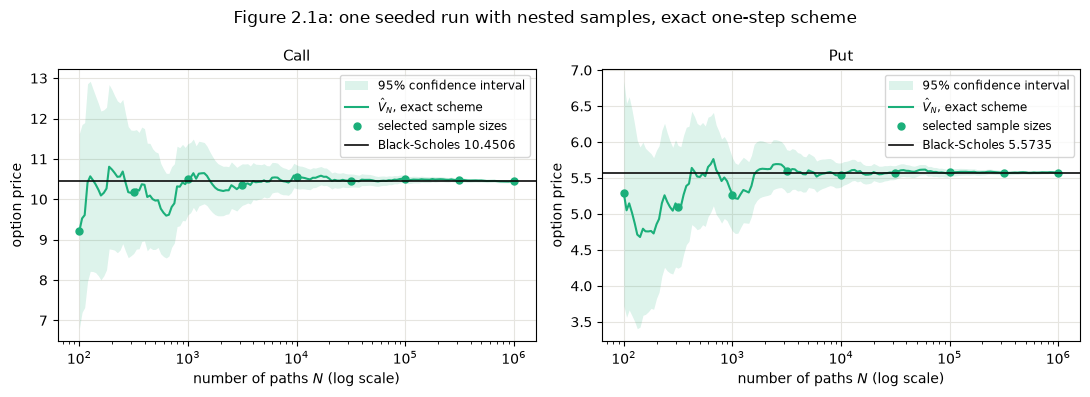

In [11]:
# Figure 2.1a: the nested estimate on a fine grid of N, with its 95% confidence band
N_fine = np.unique(np.round(np.logspace(2, 6, 161)).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, kind in zip(axes, ('call', 'put')):
    estimates = np.array([mc_price_from_ST(ST_nested[:n_paths], K, T, r, kind) for n_paths in N_fine])
    price_curve, se_curve = estimates[:, 0], estimates[:, 1]
    ax.fill_between(N_fine, price_curve - 1.96 * se_curve, price_curve + 1.96 * se_curve,
                    color=scheme_colours['exact'], alpha=0.15, linewidth=0, label='95% confidence interval')
    ax.plot(N_fine, price_curve, color=scheme_colours['exact'], linewidth=1.5, label=r'$\hat V_N$, exact scheme')
    ax.plot(N_half_decades, table_2_1a.loc[kind, 'price'], 'o', color=scheme_colours['exact'],
            markersize=5, label='selected sample sizes')
    ax.axhline(V_BS[kind], color=benchmark_colour, linewidth=1.2, label=f"Black-Scholes {V_BS[kind]:.4f}")
    ax.set_xscale('log')
    style_axes(ax, 'number of paths $N$ (log scale)', 'option price', kind.capitalize())
    ax.legend(fontsize=8.5, loc='upper right')
fig.suptitle('Figure 2.1a: one seeded run with nested samples, exact one-step scheme', fontsize=12)
fig.tight_layout()
plt.show()


**Table 2.1b** repeats the experiment many times. At each $N$ we make $M$ independent runs and compare their
actual error, the RMSE against $V_{\text{BS}}$, with the average SE that each run reports. We also count how often
the 95% interval contains $V_{\text{BS}}$. We use $M = 2{,}000$ runs
for $N \le 10^4$, which gives a coverage SE of about 0.5 percentage points, and fewer runs at large $N$ to save time.


In [12]:
# M independent seeded runs at each N, from a stream independent of the nested run (SEED + 21)
runs_per_N = {100: 2000, 316: 2000, 1000: 2000, 3162: 2000, 10000: 2000,
              31623: 500, 100000: 200, 316228: 100, 1000000: 50}
repetition_rng = np.random.default_rng(SEED + 21)

repetition_rows = []
for n_paths, n_runs in runs_per_N.items():
    runs = repeat_exact_runs(n_paths, n_runs, repetition_rng)
    for kind in ('call', 'put'):
        prices, ses = runs[kind][:, 0], runs[kind][:, 1]
        errors = prices - V_BS[kind]
        inside = np.abs(errors) <= 1.96 * ses                     # does this run's 95% CI contain V_BS?
        repetition_rows.append({'option': kind, 'N': n_paths, 'M runs': n_runs,
                                'RMSE': np.sqrt(np.mean(errors**2)),
                                'mean SE': ses.mean(),
                                'RMSE / mean SE': np.sqrt(np.mean(errors**2)) / ses.mean(),
                                'coverage of 95% CI': inside.mean(),
                                'coverage SE if 95%': np.sqrt(0.95 * 0.05 / n_runs),
                                'CI below V_BS': np.mean(errors < -1.96 * ses),   # interval wholly below
                                'CI above V_BS': np.mean(errors > 1.96 * ses)})   # interval wholly above
table_2_1b = pd.DataFrame(repetition_rows).set_index(['option', 'N']).sort_index()
table_2_1b[['M runs', 'RMSE', 'mean SE', 'RMSE / mean SE', 'coverage of 95% CI']].round({'RMSE': 4, 'mean SE': 4, 'RMSE / mean SE': 3, 'coverage of 95% CI': 4,
                  'coverage SE if 95%': 4, 'CI below V_BS': 4, 'CI above V_BS': 4})


M runs    RMSE  mean SE  RMSE / mean SE  coverage of 95% CI
option N                                                                   
call   100        2000  1.4893   1.4600           1.020              0.9385
       316        2000  0.8323   0.8245           1.009              0.9465
       1000       2000  0.4645   0.4651           0.999              0.9510
       3162       2000  0.2674   0.2616           1.022              0.9440
       10000      2000  0.1443   0.1472           0.980              0.9575
       31623       500  0.0823   0.0828           0.994              0.9520
       100000      200  0.0461   0.0465           0.990              0.9500
       316228      100  0.0280   0.0262           1.071              0.9100
       1000000      50  0.0150   0.0147           1.019              0.9600
put    100        2000  0.8590   0.8587           1.000              0.9460
       316        2000  0.4832   0.4850           0.996              0.9475
       1000       2000  0.2733   0.2735           0.999              0.9495
       3162       2000  0.1536   0.1539           0.998              0.9520
       10000      2000  0.0864   0.0866           0.999              0.9450
       31623       500  0.0512   0.0487           1.051              0.9340
       100000      200  0.0281   0.0274           1.024              0.9400
       316228      100  0.0171   0.0154           1.111              0.8900
       1000000      50  0.0077   0.0087           0.892              1.0000

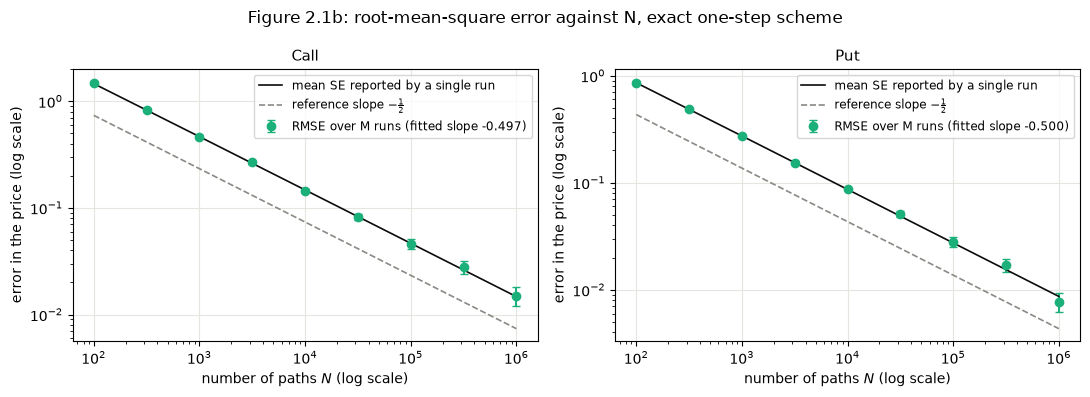

In [13]:
# Figure 2.1b: actual error (RMSE over M runs) against N, next to the SE a single run reports
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, kind in zip(axes, ('call', 'put')):
    study = table_2_1b.loc[kind]
    N_values = study.index.to_numpy()
    slope, _ = fit_power_law(N_values, study['RMSE'].to_numpy())
    # approximate 95% interval of an RMSE estimated from M runs: +- 1.96 RMSE / sqrt(2M)
    rmse_band = 1.96 * study['RMSE'] / np.sqrt(2 * study['M runs'])
    ax.errorbar(N_values, study['RMSE'], yerr=rmse_band, fmt='o', color=scheme_colours['exact'],
                markersize=6, capsize=3, label=f'RMSE over M runs (fitted slope {slope:.3f})')
    ax.plot(N_values, study['mean SE'], color=benchmark_colour, linewidth=1.2,
            label='mean SE reported by a single run')
    payoff_sd = (np.exp(-r * T) * payoff(ST_nested, K, kind)).std(ddof=1)
    ax.plot(N_values, 0.5 * payoff_sd / np.sqrt(N_values), '--', color=reference_colour, linewidth=1.2,
            label=r'reference slope $-\frac{1}{2}$')
    ax.set_xscale('log')
    ax.set_yscale('log')
    style_axes(ax, 'number of paths $N$ (log scale)', 'error in the price (log scale)', kind.capitalize())
    ax.legend(fontsize=8.5, loc='upper right')
fig.suptitle('Figure 2.1b: root-mean-square error against N, exact one-step scheme', fontsize=12)
fig.tight_layout()
plt.show()


**Table 2.1c** turns the standard error into a cost. We time a run of $10^6$ paths to get the cost per path.
The payoff standard deviation $\hat s$ comes from the $10^6$-path run, as it would from a small pilot run in
practice. The number of paths needed for a 95% half-width $h$ then follows from $1.96\,\hat s/\sqrt N = h$. As a
check on $\hat s$, the table also gives the exact standard deviation of the discounted payoff, found by
integration as in §1.4.

$$
N = \left(\frac{1.96\,\hat s}{h}\right)^2
$$


In [14]:
# Cost per path of the exact one-step estimator, and the N for a target 95% half-width
timing_rng = np.random.default_rng(SEED + 24)
seconds_per_path = best_time(lambda: mc_price_from_ST(
    simulate_terminal_exact(S0, r, sigma, T, 10**6, timing_rng), K, T, r, 'call')) / 10**6

accuracy_cost_rows = []
for kind, (pay, lower, upper) in contracts.items():
    payoff_sd = (np.exp(-r * T) * payoff(ST_nested, K, kind)).std(ddof=1)   # s-hat from 10^6 paths
    # check: the exact sd of the discounted payoff, E^Q[payoff^2] by quadrature as in §1.4
    second_moment, _ = quad(lambda s: p_tilde(s, S0, T, r, sigma) * pay(s)**2, lower, upper)
    first_moment = np.exp(r * T) * V_BS[kind]                                 # E^Q[payoff] = e^{rT} V_BS
    payoff_sd_exact = np.exp(-r * T) * np.sqrt(second_moment - first_moment**2)
    for half_width in (0.01, 0.001):
        N_needed = int(np.ceil((1.96 * payoff_sd / half_width)**2))
        accuracy_cost_rows.append({'option': kind, '95% half-width': half_width, 'payoff sd': payoff_sd,
                          'payoff sd, closed form': payoff_sd_exact,
                          'N needed': N_needed, 'time (s)': N_needed * seconds_per_path})
table_2_1c = pd.DataFrame(accuracy_cost_rows).set_index(['option', '95% half-width'])
print(f"Measured cost of the exact one-step estimator: {seconds_per_path * 1e9:.0f} ns per path")
table_2_1c.round({'payoff sd': 4, 'payoff sd, closed form': 4, 'time (s)': 2})


Measured cost of the exact one-step estimator: 13 ns per path


payoff sd  payoff sd, closed form   N needed  time (s)
option 95% half-width                                                        
call   0.010             14.7342                 14.7194    8340012      0.11
       0.001             14.7342                 14.7194  834001129     10.62
put    0.010              8.6579                  8.6576    2879632      0.04
       0.001              8.6579                  8.6576  287963159      3.67

**Reading the results.** The estimates approach the Black–Scholes prices as the sample grows
(Figure 2.1a). Repeated runs give fitted error slopes of −0.497 for the call and −0.500 for the put, close
to the predicted $-\tfrac12$ (Figure 2.1b). Their RMSE also agrees closely with the average reported SE.
With only 100 paths, the call's interval covers the benchmark in 93.85% of runs, below the nominal 95%;
at 1,000 paths coverage is 95.1% (Table 2.1b). The normal approximation therefore needs more care at small
sample sizes. Precision remains expensive: a 95% half-width of one cent needs about 8.3 million call paths,
and reducing that width by a factor of ten needs a hundred times as many (Table 2.1c).


### 2.2 Convergence in $\delta t$: strong and weak error

Now we turn to the time step. We run Euler, Milstein and the exact scheme on the same random draws, with
$n = 1, 2, 4, \dots, 512$ steps ($\delta t = T/n$) and $N = 200{,}000$ paths at each $n$. The exact scheme gives
the true $S_T$ on every path, so we can measure both kinds of error of §1.8 directly against it:

| Error | What it measures | §1.8 predicts | Shown in |
|---|---|---|---|
| strong | how far each simulated path ends from the exact one | order $\tfrac12$ for Euler, 1 for Milstein | Figure 2.2a, Table 2.2a |
| weak | the bias in the option price | order 1 for both | Figure 2.2b, Table 2.2a |

The price bias is small next to the sampling noise of a price, so we measure it on the payoff difference $D$
between each scheme and the exact scheme on the same path (common random numbers); the mean of $D$ is the weak
error. We then take up the open question of §1.8, whether Milstein's better paths give better prices, at equal
compute (Table 2.2b) and in the error budget of §1.7 (Table 2.2c, Figure 2.2c).

$$
D = e^{-r(T-t)}\big[f(\hat S_T) - f(S_T)\big]
$$


In [15]:
def terminal_prices_by_scheme(S0, r, sigma, T, n_steps, n_paths, rng, max_draws=250_000):
    # S_T under Euler, Milstein and the exact scheme (§1.8), all three driven by the same draws Z.
    # Paths are simulated in batches of rows so that at most about max_draws normals are held at once
    # (small batches also keep each path array in the processor cache); the rows of Z are drawn in order,
    # so the batches together hold exactly the draws of one big Z.
    batch_size = max(1, max_draws // n_steps)
    ST_parts = {name: [] for name in SCHEMES}
    for start in range(0, n_paths, batch_size):
        Z_batch = rng.standard_normal((min(batch_size, n_paths - start), n_steps))
        for name, scheme in SCHEMES.items():
            ST_parts[name].append(scheme(S0, r, sigma, T, Z_batch)[:, -1])    # keep only S_T
    return {name: np.concatenate(parts) for name, parts in ST_parts.items()}


def mean_and_se(x):
    # Sample mean and its standard error s / sqrt(N) (§1.6).
    return x.mean(), x.std(ddof=1) / np.sqrt(x.size)


def first_order_constant(dt, error):
    # The constant a in |error| = a dt when the slope is fixed at 1: the geometric mean of |error| / dt.
    return np.exp(np.mean(np.log(np.abs(error) / dt)))


def fit_noise(dt, mean_error, se_error, rng, n_draws=1000):
    # Noise in a fitted order and in the constant a: perturb each measured error by its own SE (one plausible
    # re-run of the ladder), refit, and repeat. Returns the standard deviations of the refitted slope and a.
    slopes, constants = np.empty(n_draws), np.empty(n_draws)
    for k in range(n_draws):
        perturbed_error = mean_error + se_error * rng.standard_normal(mean_error.size)
        slopes[k] = fit_power_law(dt, np.abs(perturbed_error))[0]
        constants[k] = first_order_constant(dt, perturbed_error)
    return slopes.std(ddof=1), constants.std(ddof=1)


In [16]:
# Strong and weak error ladder: n = 1, 2, 4, ..., 512 steps, N = 200,000 fresh paths at each n
ladder_steps = 2 ** np.arange(10)
ladder_paths = 200_000
ladder_rng = np.random.default_rng(SEED + 22)

ladder_rows = []
for n_time_steps in ladder_steps:
    ST_ladder = terminal_prices_by_scheme(S0, r, sigma, T, n_time_steps, ladder_paths, ladder_rng)
    if n_time_steps == 16:
        ST_ladder_16 = ST_ladder                                    # kept for the right panel of Figure 2.2a
    for scheme in ('euler', 'milstein'):
        row = {'scheme': scheme, 'n': n_time_steps, 'dt': T / n_time_steps}
        # strong error: mean distance from the exact S_T of the same Brownian path
        row['strong'], row['strong SE'] = mean_and_se(np.abs(ST_ladder[scheme] - ST_ladder['exact']))
        # weak error: mean of the discounted payoff difference D on the same draws
        for kind in ('call', 'put'):
            payoff_difference = np.exp(-r * T) * (payoff(ST_ladder[scheme], K, kind)
                                                  - payoff(ST_ladder['exact'], K, kind))
            row[kind], row[kind + ' SE'] = mean_and_se(payoff_difference)
        # forward: the same for f(S) = S, discounted
        row['forward'], row['forward SE'] = mean_and_se(np.exp(-r * T) * (ST_ladder[scheme] - ST_ladder['exact']))
        ladder_rows.append(row)

ladder = pd.DataFrame(ladder_rows)
# the exact forward bias, the same for both schemes: e^{-rT} S0 [(1 + r dt)^n - e^{rT}]
ladder['forward, analytic'] = np.exp(-r * T) * S0 * ((1 + r * ladder['dt'])**ladder['n'] - np.exp(r * T))
# points used in the fits: n >= 4 (the small-dt regime the orders describe) and, for the weak errors,
# a mean at least 3 SE from zero, so that the noise does not bend the fitted line
for quantity in ('strong', 'call', 'put'):
    ladder[quantity + ' fitted'] = (ladder['n'] >= 4) & (ladder[quantity].abs() >= 3 * ladder[quantity + ' SE'])
print(f"Ladder done: {len(ladder_steps)} step sizes x {ladder_paths:,} paths, three schemes on shared draws.")


Ladder done: 10 step sizes x 200,000 paths, three schemes on shared draws.


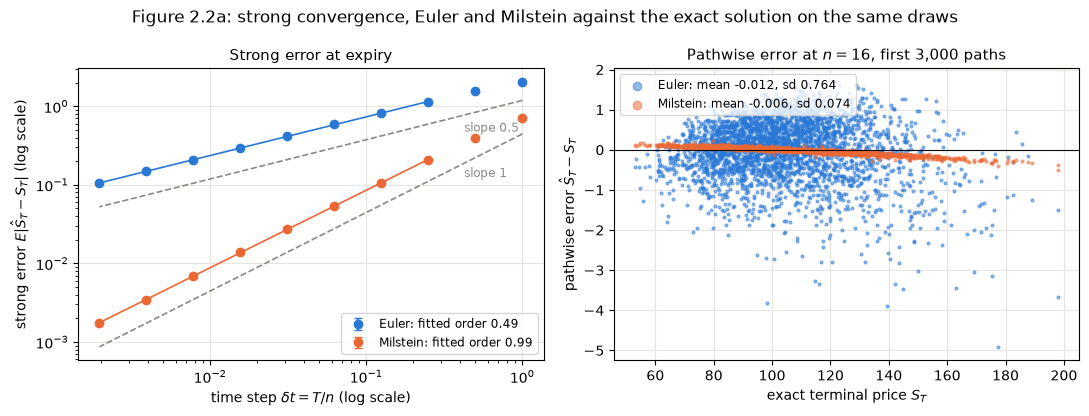

In [17]:
# Figure 2.2a: strong error against dt, and the pathwise errors behind it at n = 16
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
for scheme, order in (('euler', 0.5), ('milstein', 1.0)):
    rows_s = ladder[ladder['scheme'] == scheme]
    dt_s, err_s = rows_s['dt'].to_numpy(), rows_s['strong'].to_numpy()
    used = rows_s['strong fitted'].to_numpy()
    slope, C_fit = fit_power_law(dt_s[used], err_s[used])
    ax.errorbar(dt_s, err_s, yerr=1.96 * rows_s['strong SE'], fmt='o', color=scheme_colours[scheme],
                markersize=6, capsize=3, label=f'{scheme.capitalize()}: fitted order {slope:.2f}')
    ax.plot(dt_s[used], C_fit * dt_s[used]**slope, color=scheme_colours[scheme], linewidth=1.2)
    # reference slope (theory), drawn parallel to the data and a factor 2 below it
    ax.plot(dt_s, 0.5 * err_s[-1] * (dt_s / dt_s[-1])**order, '--', color=reference_colour, linewidth=1.2)
    ax.annotate(f'slope {order:g}', (dt_s[1], 0.5 * err_s[-1] * (dt_s[1] / dt_s[-1])**order),
                textcoords='offset points', xytext=(-8, -14), fontsize=8.5, color=reference_colour)
ax.set_xscale('log')
ax.set_yscale('log')
style_axes(ax, r'time step $\delta t = T/n$ (log scale)', r'strong error $E|\hat S_T - S_T|$ (log scale)',
           'Strong error at expiry')
ax.legend(fontsize=8.5, loc='lower right')

ax = axes[1]
n_show = 3000                                                       # first 3,000 paths of the n = 16 run
for scheme in ('euler', 'milstein'):
    pathwise_error = ST_ladder_16[scheme][:n_show] - ST_ladder_16['exact'][:n_show]
    ax.scatter(ST_ladder_16['exact'][:n_show], pathwise_error, s=4, alpha=0.5, color=scheme_colours[scheme],
               label=f'{scheme.capitalize()}: mean {pathwise_error.mean():+.3f}, sd {pathwise_error.std():.3f}')
ax.axhline(0, color=benchmark_colour, linewidth=0.8)
style_axes(ax, r'exact terminal price $S_T$', r'pathwise error $\hat S_T - S_T$',
           r'Pathwise error at $n = 16$, first 3,000 paths')
ax.legend(fontsize=8.5, loc='upper left', markerscale=3)
fig.suptitle('Figure 2.2a: strong convergence, Euler and Milstein against the exact solution on the same draws',
             fontsize=12)
fig.tight_layout()
plt.show()


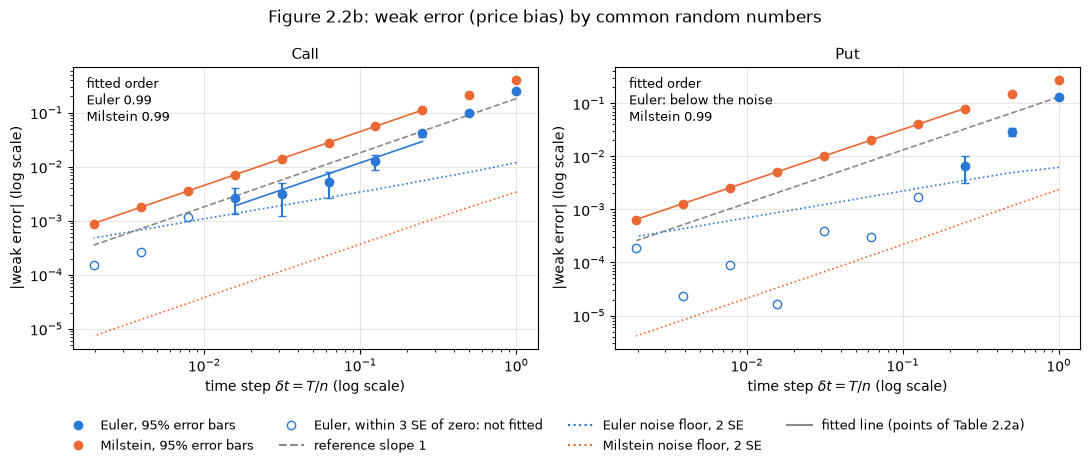

In [18]:
# Figure 2.2b: |weak error| against dt for the call and the put
from matplotlib.lines import Line2D

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, kind in zip(axes, ('call', 'put')):
    fitted_orders = []
    for scheme in ('euler', 'milstein'):
        rows_s = ladder[ladder['scheme'] == scheme]
        dt_s = rows_s['dt'].to_numpy()
        bias, bias_se = rows_s[kind].abs().to_numpy(), rows_s[kind + ' SE'].to_numpy()
        resolved = bias >= 3 * bias_se                              # filled markers: clearly above the noise
        ax.errorbar(dt_s[resolved], bias[resolved], yerr=1.96 * bias_se[resolved], fmt='o',
                    color=scheme_colours[scheme], markersize=6, capsize=3)
        ax.plot(dt_s[~resolved], bias[~resolved], 'o', markerfacecolor='white',
                markeredgecolor=scheme_colours[scheme], markersize=6)      # hollow markers: within 3 SE of zero
        ax.plot(dt_s, 2 * bias_se, ':', color=scheme_colours[scheme], linewidth=1.2)   # noise floor, 2 SE
        used = rows_s[kind + ' fitted'].to_numpy()                  # the points of the fit in Table 2.2a
        if used.sum() >= 2:
            slope, C_fit = fit_power_law(dt_s[used], bias[used])
            ax.plot(dt_s[used], C_fit * dt_s[used]**slope, color=scheme_colours[scheme], linewidth=1.2)
            fitted_orders.append(f'{scheme.capitalize()} {slope:.2f}')
        else:
            fitted_orders.append(f'{scheme.capitalize()}: below the noise')
    # reference slope 1, drawn parallel to the Milstein points and below them
    rows_m = ladder[ladder['scheme'] == 'milstein']
    dt_m = rows_m['dt'].to_numpy()
    ax.plot(dt_m, 0.4 * rows_m[kind].abs().to_numpy()[-1] * dt_m / dt_m[-1], '--', color=reference_colour,
            linewidth=1.2)
    ax.text(0.03, 0.97, 'fitted order\n' + '\n'.join(fitted_orders), transform=ax.transAxes, va='top', fontsize=9)
    ax.set_xscale('log')
    ax.set_yscale('log')
    style_axes(ax, r'time step $\delta t = T/n$ (log scale)', '|weak error| (log scale)', kind.capitalize())

# one legend for both panels, below them, built from one sample marker or line per entry
legend_handles = [
    Line2D([], [], marker='o', linestyle='', color=scheme_colours['euler'], label='Euler, 95% error bars'),
    Line2D([], [], marker='o', linestyle='', color=scheme_colours['milstein'], label='Milstein, 95% error bars'),
    Line2D([], [], marker='o', linestyle='', markerfacecolor='white', markeredgecolor=scheme_colours['euler'],
           label='Euler, within 3 SE of zero: not fitted'),
    Line2D([], [], color=reference_colour, linestyle='--', label='reference slope 1'),
    Line2D([], [], color=scheme_colours['euler'], linestyle=':', label='Euler noise floor, 2 SE'),
    Line2D([], [], color=scheme_colours['milstein'], linestyle=':', label='Milstein noise floor, 2 SE'),
    Line2D([], [], color=reference_colour, linestyle='-', label='fitted line (points of Table 2.2a)'),
]
fig.legend(handles=legend_handles, loc='lower center', ncol=4, fontsize=9, frameon=False)
fig.suptitle('Figure 2.2b: weak error (price bias) by common random numbers', fontsize=12)
fig.tight_layout(rect=(0, 0.11, 1, 1))
plt.show()


**Table 2.2a** puts the fitted orders beside the theory of §1.8. Each order is the slope of log error against
$\log\delta t$, fitted from $n = 4$ upwards, since the orders describe small $\delta t$. For the weak errors we keep
only points at least 3 SE away from zero, so that pure noise does not bend the line; the table lists the points
used. The constant $a$ is the one in $|\text{weak error}| \approx a\,\delta t$, which the error budget below needs.
Each fitted value comes with a noise SE, found by refitting 1,000 times with every point jittered by its own
standard error.


In [19]:
# Table 2.2a: fitted orders of convergence against theory, with their noise SE
theoretical_orders = {('strong', 'euler'): 0.5, ('strong', 'milstein'): 1.0, ('call', 'euler'): 1.0,
          ('call', 'milstein'): 1.0, ('put', 'euler'): 1.0, ('put', 'milstein'): 1.0}
error_labels = {'strong': 'strong error', 'call': 'weak error, call', 'put': 'weak error, put'}
fit_noise_rng = np.random.default_rng(SEED + 25)
order_rows = []
weak_constant = {}                                                  # a in |weak error| = a dt, per (option, scheme)
for (quantity, scheme), order in theoretical_orders.items():
    rows_s = ladder[(ladder['scheme'] == scheme) & ladder[quantity + ' fitted']]
    n_used = rows_s['n'].to_list()
    row = {'error': error_labels[quantity], 'scheme': scheme.capitalize(), 'theoretical order': order,
           'fitted order': np.nan, 'noise SE of order': np.nan, 'points used (n)': '–',
           'a (slope fixed at 1)': np.nan, 'noise SE of a': np.nan}
    if len(n_used) >= 2:
        dt_used = rows_s['dt'].to_numpy()
        error_used, se_used = rows_s[quantity].to_numpy(), rows_s[quantity + ' SE'].to_numpy()
        order_noise, constant_noise = fit_noise(dt_used, error_used, se_used, fit_noise_rng)
        row['fitted order'] = fit_power_law(dt_used, np.abs(error_used))[0]
        row['noise SE of order'] = order_noise
        row['points used (n)'] = f'{n_used[0]}–{n_used[-1]} ({len(n_used)} points)'
        if quantity != 'strong':
            weak_constant[(quantity, scheme)] = first_order_constant(dt_used, error_used)
            row['a (slope fixed at 1)'] = weak_constant[(quantity, scheme)]
            row['noise SE of a'] = constant_noise
    order_rows.append(row)
table_2_2a = pd.DataFrame(order_rows).set_index(['error', 'scheme'])
table_2_2a.round({'fitted order': 2, 'noise SE of order': 4, 'a (slope fixed at 1)': 3,
                  'noise SE of a': 4}).fillna('–')


/var/folders/fv/8kgvjzz53_s0kstrbq5d16vw0000gn/T/ipykernel_18619/1527224338.py:28: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  'noise SE of a': 4}).fillna('–')


theoretical order fitted order noise SE of order  \
error            scheme                                                       
strong error     Euler                   0.5         0.49            0.0004   
                 Milstein                1.0         0.99            0.0005   
weak error, call Euler                   1.0         0.99            0.1029   
                 Milstein                1.0         0.99            0.0009   
weak error, put  Euler                   1.0            –                 –   
                 Milstein                1.0         0.99            0.0008   

                            points used (n) a (slope fixed at 1) noise SE of a  
error            scheme                                                         
strong error     Euler     4–512 (8 points)                    –             –  
                 Milstein  4–512 (8 points)                    –             –  
weak error, call Euler      4–64 (5 points)                0.119        0.0135  
                 Milstein  4–512 (8 points)                0.452        0.0007  
weak error, put  Euler                    –                    –             –  
                 Milstein  4–512 (8 points)                0.327        0.0004

**Checks on the error estimates.** For $f(S)=S$, each numerical step has mean growth
$1+r\,\delta t$, so the expected terminal stock price is known:

$$
\mathbb E[\hat S_T]=S_0(1+r\,\delta t)^n.
$$

We compare the simulated forward bias with this expression. With a single step, each scheme's option
price is also a one-dimensional integral over the normal draw, which we evaluate independently with
`quad`. The convergence figures show the full ladder; the checks below test its implementation.


In [20]:
# Exact check 1: the forward bias, measured on common random numbers against its closed form
for scheme in ('euler', 'milstein'):
    rows_s = ladder[ladder['scheme'] == scheme]
    gap_in_se = ((rows_s['forward'] - rows_s['forward, analytic']).abs() / rows_s['forward SE']).max()
    print(f"{scheme.capitalize():8s} forward bias: largest |measured - analytic| over n = 1..512 is {gap_in_se:.2f} SE")

# Exact check 2: n = 1, the scheme price as a one-dimensional integral over phi ~ N(0, 1)
one_step = {'euler': lambda phi: S0 * (1 + r * T + sigma * np.sqrt(T) * phi),
            'milstein': lambda phi: S0 * (1 + r * T + sigma * np.sqrt(T) * phi + 0.5 * sigma**2 * T * (phi**2 - 1))}
print("\nOne step (n = 1): weak error by quadrature against the common-random-numbers estimate")
for scheme, ST_of_phi in one_step.items():
    for kind in ('call', 'put'):
        integral, _ = quad(lambda phi: payoff(ST_of_phi(phi), K, kind) * norm.pdf(phi), -12, 12, limit=200,
                           points=[-1.5, -0.25, 0.0, 0.25])     # the payoff kinks lie near these phi
        exact_bias = np.exp(-r * T) * integral - V_BS[kind]
        measured = ladder[(ladder['scheme'] == scheme) & (ladder['n'] == 1)].iloc[0]
        print(f"  {scheme.capitalize():8s} {kind:4s}  quadrature {exact_bias:+.4f}   simulated {measured[kind]:+.4f}"
              f" +- {measured[kind + ' SE']:.4f}   difference {(measured[kind] - exact_bias) / measured[kind + ' SE']:+.2f} SE")


Euler    forward bias: largest |measured - analytic| over n = 1..512 is 2.10 SE
Milstein forward bias: largest |measured - analytic| over n = 1..512 is 2.52 SE

One step (n = 1): weak error by quadrature against the common-random-numbers estimate
  Euler    call  quadrature -0.2468   simulated -0.2501 +- 0.0060   difference -0.54 SE
  Euler    put   quadrature -0.1259   simulated -0.1290 +- 0.0031   difference -0.99 SE
  Milstein call  quadrature -0.3967   simulated -0.3989 +- 0.0017   difference -1.29 SE
  Milstein put   quadrature -0.2758   simulated -0.2729 +- 0.0012   difference +2.45 SE


**Table 2.2b** compares the schemes at equal compute. We time each scheme on the same $20{,}000 \times 252$
matrix of draws, and time the drawing of the normals separately, since in practice each scheme needs its own
draws. Using the fits of Table 2.2a, the table then gives the steps $n$ each scheme needs to reach a strong error
of 0.01 and a call bias of 0.001, and the time per path that costs.


In [21]:
# Table 2.2b: measured cost per path-step, and the cost of reaching a target accuracy
Z_timing = np.random.default_rng(SEED + 24).standard_normal((20_000, 252))
draw_cost = best_time(lambda: np.random.default_rng(SEED + 24).standard_normal((20_000, 252))) / Z_timing.size
scheme_cost = {}
for name, scheme in SCHEMES.items():
    # best_time calls the lambda straight away, inside this pass of the loop, so it times this scheme
    scheme_cost[name] = best_time(lambda: scheme(S0, r, sigma, T, Z_timing)) / Z_timing.size

strong_target, call_bias_target = 0.01, 0.001
step_cost_rows = []
for name in ('euler', 'milstein', 'exact'):
    per_step = scheme_cost[name] + draw_cost
    row = {'scheme': name.capitalize(), 'scheme only (ns per path-step)': 1e9 * scheme_cost[name],
           'with the draws (ns per path-step)': 1e9 * per_step}
    if name == 'exact':
        steps_strong, steps_weak = 1, 1                             # no discretisation error at any dt
    else:
        rows_s = ladder[(ladder['scheme'] == name) & ladder['strong fitted']]
        slope, C_fit = fit_power_law(rows_s['dt'].to_numpy(), rows_s['strong'].to_numpy())
        steps_strong = int(np.ceil(T / (strong_target / C_fit)**(1 / slope)))      # solve C_fit dt^slope = target
        steps_weak = int(np.ceil(T * weak_constant[('call', name)] / call_bias_target))   # a dt = target
    row['n for strong error 0.01'] = steps_strong
    row['time per path (µs), strong 0.01'] = 1e6 * steps_strong * per_step
    row['n for call bias 0.001'] = steps_weak
    row['time per path (µs), call bias 0.001'] = 1e6 * steps_weak * per_step
    step_cost_rows.append(row)
table_2_2c = pd.DataFrame(step_cost_rows).set_index('scheme')
print(f"Drawing the normals: {1e9 * draw_cost:.1f} ns per path-step; "
      f"Milstein / Euler cost per path-step with the draws: "
      f"{(scheme_cost['milstein'] + draw_cost) / (scheme_cost['euler'] + draw_cost):.2f}")
table_2_2c.round({'scheme only (ns per path-step)': 1, 'with the draws (ns per path-step)': 1,
                  'time per path (µs), strong 0.01': 3, 'time per path (µs), call bias 0.001': 3})


Drawing the normals: 5.7 ns per path-step; Milstein / Euler cost per path-step with the draws: 1.26


,scheme only (ns per path-step),with the draws (ns per path-step),n for strong error 0.01,"time per path (µs), strong 0.01",n for call bias 0.001,"time per path (µs), call bias 0.001"
scheme,,,,,,
Euler,6.2,12.0,61603,738.262,119,1.426
Milstein,9.4,15.1,88,1.331,452,6.835
Exact,6.5,12.2,1,0.012,1,0.012


**Table 2.2c** checks the error budget at the settings of §1.10: daily steps ($n = 252$) and $N = 100{,}000$
paths, on the same draws as there. So the first column repeats the 252-step prices of §1.10. The last column
divides the time-step bias (the mean of $D$) by the price SE.


In [22]:
# Table 2.2c: daily-step bias against the sampling error at N = 100,000 (the draws of §1.10)
ST_daily = terminal_prices_by_scheme(S0, r, sigma, T, 252, 100_000, np.random.default_rng(SEED))
daily_rows = []
for kind in ('call', 'put'):
    for scheme in ('euler', 'milstein'):
        price_daily, se_daily = mc_price_from_ST(ST_daily[scheme], K, T, r, kind)
        payoff_difference = np.exp(-r * T) * (payoff(ST_daily[scheme], K, kind)
                                              - payoff(ST_daily['exact'], K, kind))
        bias_daily, bias_se = mean_and_se(payoff_difference)
        daily_rows.append({'option': kind, 'scheme': scheme.capitalize(), 'price, 252 steps': price_daily,
                           'price SE': se_daily, 'weak error': bias_daily, 'weak error SE': bias_se,
                           '|weak error| / price SE': abs(bias_daily) / se_daily,
                           'first-order prediction -a dt': -weak_constant.get((kind, scheme), np.nan) * T / 252})
table_2_2d = pd.DataFrame(daily_rows).set_index(['option', 'scheme'])
table_2_2d_display = table_2_2d.round({'price, 252 steps': 4, 'price SE': 4, 'weak error': 5, 'weak error SE': 5,
                                       '|weak error| / price SE': 3})
# '–' where no constant a could be fitted (the Euler put's bias is below the noise at n >= 8)
table_2_2d_display['first-order prediction -a dt'] = [('–' if np.isnan(x) else f'{x:.5f}')
                                                      for x in table_2_2d['first-order prediction -a dt']]
table_2_2d_display


price, 252 steps  price SE  weak error  weak error SE  \
option scheme                                                            
call   Euler              10.3584    0.0462     0.00021        0.00048   
       Milstein           10.3564    0.0462    -0.00178        0.00001   
put    Euler               5.6124    0.0274    -0.00009        0.00031   
       Milstein            5.6112    0.0274    -0.00131        0.00001   

                 |weak error| / price SE first-order prediction -a dt  
option scheme                                                          
call   Euler                       0.004                     -0.00047  
       Milstein                    0.039                     -0.00179  
put    Euler                       0.003                            –  
       Milstein                    0.048                     -0.00130

**Figure 2.2c** compares allocations of a fixed budget using the measured
call-bias constants $a$ and payoff standard deviation $b=\hat s$. We choose the time step by minimising the
error proxy $a\,\delta t+b/\sqrt N$: the magnitude of the bias plus one standard error. With the one-year
expiry used here, $K_{\text{Compute}}=N/\delta t$, so this proxy becomes
$a\,\delta t+b/\sqrt{K_{\text{Compute}}\delta t}$. Differentiating with respect to $\delta t$ gives

$$
a-\frac{b}{2\sqrt{K_{\text{Compute}}}}\delta t^{-3/2}=0,
\qquad
\delta t^*=\left(\frac{b}{2a}\right)^{2/3}K_{\text{Compute}}^{-1/3},
\qquad N^*=K_{\text{Compute}}\delta t^*.
$$

We round this allocation to a whole number of steps, with a minimum of one. The figure plots the predicted
RMSE, $\sqrt{(a\delta t)^2+b^2/N}$, at that allocation. **The allocation minimises bias plus SE, not RMSE**;
the two criteria give the same asymptotic rate but different constants. At a budget of $10^6$ path-steps, the Euler allocation is six steps and 166,666 paths.
The comparison includes daily Euler
steps and exact one-step simulation, with spot checks against independent runs. The fitted bias model is
an approximation for small time steps, so its coarsest-grid predictions need particular care.


In [23]:
def optimal_split(a, b, budget, T):
    # §2.2: minimise a dt + b N^{-1/2} subject to N / dt = budget. Returns (n steps, N paths),
    # with dt* = (b / 2a)^{2/3} budget^{-1/3} rounded to a whole number of steps (at least one).
    dt_star = (b / (2 * a))**(2 / 3) * budget**(-1 / 3)
    n_star = max(1, int(round(T / dt_star)))
    return n_star, int(budget * T / n_star)


def predicted_rmse(a, b, n_steps, n_paths, T):
    # Root-mean-square error of a price with bias a dt and standard error b / sqrt(N).
    return np.sqrt((a * T / n_steps)**2 + b**2 / n_paths)


a_euler, a_milstein = weak_constant[('call', 'euler')], weak_constant[('call', 'milstein')]
b_call = (np.exp(-r * T) * payoff(ST_nested, K, 'call')).std(ddof=1)
print(f"Constants for the call: a (Euler) = {a_euler:.3f}, a (Milstein) = {a_milstein:.3f}, b = {b_call:.3f}, "
      f"b / 2a (Euler) = {b_call / (2 * a_euler):.1f}")

# Spot checks: Euler at the rounded bias-plus-SE allocation, M independent runs each (generator SEED + 23)
spot_budgets = {10**4: 1000, 10**5: 400, 10**6: 200}                 # budget -> number of runs M
spot_rng = np.random.default_rng(SEED + 23)
spot_rmse = {}
for budget, n_runs in spot_budgets.items():
    n_star, N_star = optimal_split(a_euler, b_call, budget, T)
    run_errors = np.empty(n_runs)
    for m in range(n_runs):
        ST_spot = simulate_paths(S0, r, sigma, T, n_star, N_star, spot_rng, 'euler')[:, -1]
        run_errors[m] = mc_price_from_ST(ST_spot, K, T, r, 'call')[0] - V_BS['call']
    spot_rmse[budget] = np.sqrt(np.mean(run_errors**2))

budget_rows = []
for budget in 10.0 ** np.arange(4, 10):
    budget = int(budget)
    n_e, N_e = optimal_split(a_euler, b_call, budget, T)
    n_m, N_m = optimal_split(a_milstein, b_call, budget, T)
    euler_rmse = predicted_rmse(a_euler, b_call, n_e, N_e, T)
    exact_rmse = b_call / np.sqrt(budget)
    simulated_exact = (table_2_1b.loc[('call', budget), 'RMSE'] if ('call', budget) in table_2_1b.index else np.nan)
    budget_rows.append({'K_Compute': budget, 'Euler n*': n_e, 'Euler N*': N_e, 'Euler RMSE': euler_rmse,
                        'Euler RMSE, simulated': spot_rmse.get(budget, np.nan),
                        'Milstein n*': n_m, 'Milstein RMSE': predicted_rmse(a_milstein, b_call, n_m, N_m, T),
                        'Euler daily RMSE': predicted_rmse(a_euler, b_call, 252, budget * T / 252, T),
                        'exact RMSE': exact_rmse, 'exact RMSE, simulated': simulated_exact,
                        'Euler / exact': euler_rmse / exact_rmse})
table_2_2e = pd.DataFrame(budget_rows).set_index('K_Compute')
table_2_2e_display = table_2_2e.round(4).round({'Euler / exact': 2})
for column in ('Euler RMSE, simulated', 'exact RMSE, simulated'):    # '–' where there is no spot check
    table_2_2e_display[column] = [('–' if np.isnan(x) else f'{x:.4f}') for x in table_2_2e[column]]


Constants for the call: a (Euler) = 0.119, a (Milstein) = 0.452, b = 14.734, b / 2a (Euler) = 62.0


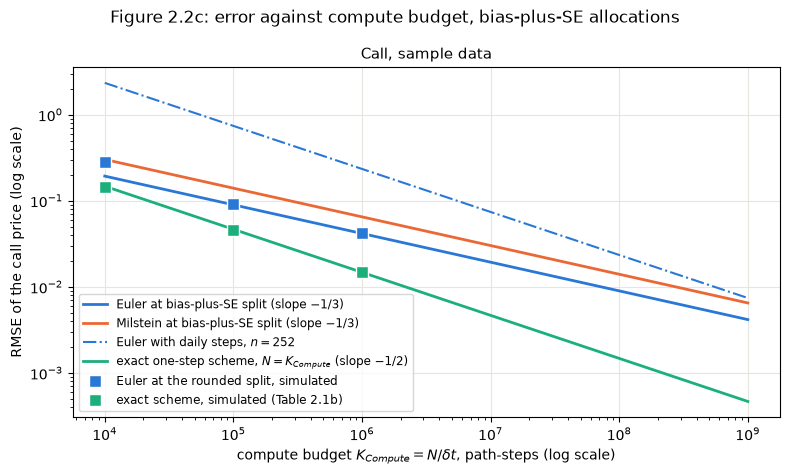

In [24]:
# Figure 2.2c: predicted RMSE against the compute budget, with the simulated spot checks
budget_grid = np.logspace(4, 9, 200)
fig, ax = plt.subplots(figsize=(8, 4.8))
for scheme, a_scheme in (('euler', a_euler), ('milstein', a_milstein)):
    dt_star = np.minimum((b_call / (2 * a_scheme))**(2 / 3) * budget_grid**(-1 / 3), T)   # at most one step
    rmse_curve = np.sqrt((a_scheme * dt_star)**2 + b_call**2 / (budget_grid * dt_star))  # N = budget dt / T, T = 1
    ax.plot(budget_grid, rmse_curve, color=scheme_colours[scheme], linewidth=2,
            label=f'{scheme.capitalize()} at bias-plus-SE split (slope $-1/3$)')
ax.plot(budget_grid, np.sqrt((a_euler * T / 252)**2 + b_call**2 * 252 / (budget_grid * T)), '-.',
        color=scheme_colours['euler'], linewidth=1.5, label='Euler with daily steps, $n = 252$')
ax.plot(budget_grid, b_call / np.sqrt(budget_grid), color=scheme_colours['exact'], linewidth=2,
        label='exact one-step scheme, $N = K_{Compute}$ (slope $-1/2$)')
spot_K = np.array(list(spot_rmse))
ax.plot(spot_K, [spot_rmse[k] for k in spot_K], 's', color=scheme_colours['euler'], markersize=8,
        markeredgecolor='white', label='Euler at the rounded split, simulated')
exact_checks = table_2_2e['exact RMSE, simulated'].dropna()
ax.plot(exact_checks.index, exact_checks, 's', color=scheme_colours['exact'], markersize=8,
        markeredgecolor='white', label='exact scheme, simulated (Table 2.1b)')
ax.set_xscale('log')
ax.set_yscale('log')
style_axes(ax, r'compute budget $K_{Compute} = N/\delta t$, path-steps (log scale)',
           'RMSE of the call price (log scale)', 'Call, sample data')
ax.legend(fontsize=8.5, loc='lower left')
fig.suptitle('Figure 2.2c: error against compute budget, bias-plus-SE allocations', fontsize=12)
fig.tight_layout()
plt.show()


**Reading the results.** Milstein's pathwise convergence is faster: its fitted strong order
is 0.99, against 0.49 for Euler (Table 2.2a). The call-price comparison goes differently. Both fitted weak
orders are close to 1, but Milstein has the larger bias constant at these parameters, 0.452 against 0.119
for Euler. Figures 2.2a–b show why path accuracy and price accuracy need separate comparisons.

At daily steps and $N=100{,}000$, the measured vanilla biases are less than 5% of the price SE (Table 2.2c).
Sampling noise is therefore the main error at those settings. Figure 2.2c shows the benefit of spending
more of a fixed budget on paths: at $10^6$ path-steps, the six-step Euler allocation has predicted RMSE
0.0412, compared with 0.2339 for daily Euler and 0.0147 for exact one-step simulation. The coarsest-budget
spot check deviates from the fitted bias model, so this allocation should be read as an approximation.


### 2.3 Antithetic variates at equal cost


**What we measure, and against what.** Section 1.9 predicts that pairing each draw $\phi$ with its mirror
image $-\phi$ makes the estimate less noisy without simulating more paths. It only works if the two payoffs of
a pair tend to move in opposite directions, that is, if their correlation $\rho$ is negative. Every comparison
keeps the total number of simulated paths $N$ fixed, so plain and antithetic sampling cost the same, and the
antithetic standard error is computed from the $N/2$ pair averages (§1.9). At equal cost, the variance falls by
the factor

$$
\frac{\mathrm{SE}^2_{\text{plain}}}{\mathrm{SE}^2_{\text{antithetic}}} = \frac{1}{1+\rho}.
$$

| Prediction (§1.9) | What we measure | Where |
|---|---|---|
| Pairing preserves each scheme's expected price and reduces sampling noise | Error against Black–Scholes, SE and variance ratio | Table 2.3a |
| Pairing removes most of the error in put–call parity | $\hat C - \hat P$ against $S_0 - Ke^{-rT}$ | Table 2.3b |
| The gain is largest deep in the money; a straddle loses | $\rho$ and the factor across strikes | Figure 2.3a |


In [25]:
import time


def mc_price(S0, K, T, r, sigma, n_paths, n_steps, scheme, kind, rng, antithetic=False):
    # Monte Carlo price and standard error (§1.6), with or without antithetic variates (§1.9).
    # n_paths counts every simulated path, so plain and antithetic runs of the same n_paths cost the same.
    # Returns (price, SE).
    if not antithetic:
        paths = simulate_paths(S0, r, sigma, T, n_steps, n_paths, rng, scheme)
        discounted_payoffs = np.exp(-r * T) * payoff(paths[:, -1], K, kind)       # one per path
    else:
        n_pairs = n_paths // 2
        Z_pairs = rng.standard_normal((n_pairs, n_steps))                         # one set of draws per pair
        paths_plus = simulate_paths(S0, r, sigma, T, n_steps, n_pairs, rng, scheme, Z=Z_pairs)
        payoffs_plus = payoff(paths_plus[:, -1], K, kind)                         # payoff on each path
        del paths_plus                                                            # free memory before the mirror run
        paths_minus = simulate_paths(S0, r, sigma, T, n_steps, n_pairs, rng, scheme, Z=-Z_pairs)
        payoffs_minus = payoff(paths_minus[:, -1], K, kind)                       # payoff on its mirror image
        discounted_payoffs = np.exp(-r * T) * 0.5 * (payoffs_plus + payoffs_minus)   # one average per pair
    price = discounted_payoffs.mean()
    standard_error = discounted_payoffs.std(ddof=1) / np.sqrt(discounted_payoffs.size)   # over paths, or over pairs
    return price, standard_error


In [26]:
# Every scheme with plain and antithetic sampling at equal cost: N = 100,000 simulated paths per run. Each run
# restarts the generator from SEED, so for a given scheme and sampling the call, put and stock share their paths.
n_paths_2_3 = 100_000
schemes_2_3 = [('exact', 1, 'exact, 1 step'), ('exact', 252, 'exact, 252 steps'),
               ('euler', 252, 'Euler, 252 steps'), ('milstein', 252, 'Milstein, 252 steps')]
estimates_2_3 = {}                                     # (option, scheme, sampling) -> (price, SE, run time)
for option in ('call', 'put', 'stock'):
    if option == 'stock':                              # the stock is a call struck at zero: it pays S_T (Table 2.3b)
        strike_2_3, kind_2_3 = 0.0, 'call'
    else:
        strike_2_3, kind_2_3 = K, option
    for scheme_name, n_steps_2_3, scheme_label in schemes_2_3:
        for sampling in ('plain', 'antithetic'):
            start = time.perf_counter()
            price_2_3, se_2_3 = mc_price(S0, strike_2_3, T, r, sigma, n_paths_2_3, n_steps_2_3, scheme_name,
                                         kind_2_3, np.random.default_rng(SEED), antithetic=(sampling == 'antithetic'))
            seconds = time.perf_counter() - start
            estimates_2_3[option, scheme_label, sampling] = (price_2_3, se_2_3, seconds)

# Table 2.3a: price, SE, 95% CI, error against Black-Scholes, and the variance ratio at equal cost
rows_2_3a = []
for (option, scheme_label, sampling), (price_2_3, se_2_3, seconds) in estimates_2_3.items():
    if option == 'stock':
        continue
    error_2_3 = price_2_3 - bs_price(S0, K, T, r, sigma, option)
    se_plain = estimates_2_3[option, scheme_label, 'plain'][1]
    rows_2_3a.append({'option': option, 'scheme': scheme_label, 'sampling': sampling,
                      'price': price_2_3, 'SE': se_2_3,
                      '95% CI lower': price_2_3 - 1.96 * se_2_3, '95% CI upper': price_2_3 + 1.96 * se_2_3,
                      'error vs BS': error_2_3, '|error|/SE': abs(error_2_3) / se_2_3,
                      'variance ratio': (se_plain / se_2_3)**2,                  # 1 for the plain rows
                      'run time (s)': seconds})
table_2_3a = pd.DataFrame(rows_2_3a).set_index(['option', 'scheme', 'sampling'])


**Table 2.3a: plain and antithetic Monte Carlo prices under each scheme, at equal cost.** Each row uses
$N = 100{,}000$ simulated paths (50,000 antithetic pairs) and seed `SEED`. The Black–Scholes benchmark is
$C = 10.4506$, $P = 5.5735$. The variance ratio is $\mathrm{SE}^2_{\text{plain}}/\mathrm{SE}^2_{\text{antithetic}}$ at
the same $N$ (1 for the plain rows). It tells us how many times fewer paths antithetic sampling needs for the
same standard error. Run times are wall-clock seconds and vary from run to run.


In [27]:
table_2_3a[['price', 'SE', 'error vs BS', '|error|/SE', 'variance ratio', 'run time (s)']].round(4).round({'|error|/SE': 2, 'variance ratio': 2, 'run time (s)': 3})


price      SE  error vs BS  \
option scheme              sampling                                   
call   exact, 1 step       plain       10.5021  0.0468       0.0515   
                           antithetic  10.4820  0.0330       0.0314   
       exact, 252 steps    plain       10.3582  0.0462      -0.0924   
                           antithetic  10.4258  0.0327      -0.0248   
       Euler, 252 steps    plain       10.3584  0.0462      -0.0922   
                           antithetic  10.4258  0.0327      -0.0248   
       Milstein, 252 steps plain       10.3564  0.0462      -0.0942   
                           antithetic  10.4240  0.0327      -0.0266   
put    exact, 1 step       plain        5.5764  0.0273       0.0029   
                           antithetic   5.5924  0.0210       0.0189   
       exact, 252 steps    plain        5.6125  0.0274       0.0390   
                           antithetic   5.5609  0.0209      -0.0127   
       Euler, 252 steps    plain        5.6124  0.0274       0.0389   
                           antithetic   5.5605  0.0209      -0.0130   
       Milstein, 252 steps plain        5.6112  0.0274       0.0377   
                           antithetic   5.5596  0.0209      -0.0140   

                                       |error|/SE  variance ratio  \
option scheme              sampling                                 
call   exact, 1 step       plain             1.10            1.00   
                           antithetic        0.95            2.00   
       exact, 252 steps    plain             2.00            1.00   
                           antithetic        0.76            2.00   
       Euler, 252 steps    plain             2.00            1.00   
                           antithetic        0.76            2.00   
       Milstein, 252 steps plain             2.04            1.00   
                           antithetic        0.81            2.00   
put    exact, 1 step       plain             0.11            1.00   
                           antithetic        0.90            1.70   
       exact, 252 steps    plain             1.42            1.00   
                           antithetic        0.61            1.73   
       Euler, 252 steps    plain             1.42            1.00   
                           antithetic        0.62            1.73   
       Milstein, 252 steps plain             1.37            1.00   
                           antithetic        0.67            1.73   

                                       run time (s)  
option scheme              sampling                  
call   exact, 1 step       plain              0.002  
                           antithetic         0.002  
       exact, 252 steps    plain              0.534  
                           antithetic         0.321  
       Euler, 252 steps    plain              0.398  
                           antithetic         0.267  
       Milstein, 252 steps plain              0.599  
                           antithetic         0.357  
put    exact, 1 step       plain              0.002  
                           antithetic         0.002  
       exact, 252 steps    plain              0.304  
                           antithetic         0.236  
       Euler, 252 steps    plain              0.351  
                           antithetic         0.250  
       Milstein, 252 steps plain              0.448  
                           antithetic         0.342

**Table 2.3b: put–call parity on the Monte Carlo prices.** Each call and put in Table 2.3a was priced on the
same paths. Parity says $C - P = S_0 - Ke^{-rT} = 4.8771$, and the "parity residual" is how far $\hat C - \hat P$
misses it. Path by path, the call payoff minus the put payoff is simply $S_T - K$, so the residual should equal
the error in the simulated discounted stock price, $e^{-rT}\,\overline{S_T} - S_0$. We estimate that error
separately, with its own standard error, by pricing the stock as a call struck at zero. The last column is the
bias each scheme carries by construction: zero for the exact scheme, and
$S_0\big[(1 + r\,\delta t)^n e^{-rT} - 1\big]$ for Euler and Milstein.


In [28]:
# Put-call parity residual of the Monte Carlo prices, and the martingale estimate e^{-rT} mean(S_T) - S0 behind it
rows_2_3b = []
for scheme_name, n_steps_2_3, scheme_label in schemes_2_3:
    for sampling in ('plain', 'antithetic'):
        call_mc = estimates_2_3['call', scheme_label, sampling][0]
        put_mc = estimates_2_3['put', scheme_label, sampling][0]
        stock_mc, stock_se = estimates_2_3['stock', scheme_label, sampling][:2]
        parity_residual = (call_mc - put_mc) - (S0 - K * np.exp(-r * T))
        # E[e^{-rT} S_T] under the scheme: S0 exactly, or S0 (1 + r dt)^n e^{-rT} for Euler and Milstein
        scheme_mean = S0 if scheme_name == 'exact' else S0 * (1 + r * T / n_steps_2_3)**n_steps_2_3 * np.exp(-r * T)
        rows_2_3b.append({'scheme': scheme_label, 'sampling': sampling, 'C - P': call_mc - put_mc,
                          'parity residual': parity_residual, 'e^(-rT) mean(S_T) - S0': stock_mc - S0,
                          'SE': stock_se, 'residual/SE': parity_residual / stock_se,
                          'scheme bias': scheme_mean - S0})
table_2_3b = pd.DataFrame(rows_2_3b).set_index(['scheme', 'sampling'])
table_2_3b.round(4).round({'residual/SE': 2})


C - P  parity residual  \
scheme              sampling                              
exact, 1 step       plain       4.9257           0.0486   
                    antithetic  4.8896           0.0125   
exact, 252 steps    plain       4.7457          -0.1314   
                    antithetic  4.8650          -0.0121   
Euler, 252 steps    plain       4.7460          -0.1311   
                    antithetic  4.8653          -0.0118   
Milstein, 252 steps plain       4.7452          -0.1318   
                    antithetic  4.8645          -0.0126   

                                e^(-rT) mean(S_T) - S0      SE  residual/SE  \
scheme              sampling                                                  
exact, 1 step       plain                       0.0486  0.0641         0.76   
                    antithetic                  0.0125  0.0128         0.98   
exact, 252 steps    plain                      -0.1314  0.0637        -2.06   
                    antithetic                 -0.0121  0.0126        -0.96   
Euler, 252 steps    plain                      -0.1311  0.0636        -2.06   
                    antithetic                 -0.0118  0.0125        -0.94   
Milstein, 252 steps plain                      -0.1318  0.0636        -2.07   
                    antithetic                 -0.0126  0.0126        -1.00   

                                scheme bias  
scheme              sampling                 
exact, 1 step       plain            0.0000  
                    antithetic       0.0000  
exact, 252 steps    plain            0.0000  
                    antithetic       0.0000  
Euler, 252 steps    plain           -0.0005  
                    antithetic      -0.0005  
Milstein, 252 steps plain           -0.0005  
                    antithetic      -0.0005

In [29]:
# One Euler step is linear in phi, S_T = S0 (1 + rT + sigma sqrt(T) phi), so each antithetic pair averages to
# S0 (1 + rT) exactly: the martingale estimate has no sampling error left, only the Euler bias.
stock_euler_1, stock_euler_1_se = mc_price(S0, 0.0, T, r, sigma, n_paths_2_3, 1, 'euler', 'call',
                                           np.random.default_rng(SEED), antithetic=True)
euler_1_bias = S0 * ((1 + r * T) * np.exp(-r * T) - 1)
print(f"Euler, 1 step, antithetic:  e^(-rT) mean(S_T) - S0 = {stock_euler_1 - S0:.4f}   SE = {stock_euler_1_se:.1e}   "
      f"S0[(1 + rT) e^(-rT) - 1] = {euler_1_bias:.4f}")

# The stock under the exact scheme: Corr[S_T(phi), S_T(-phi)] = -exp(-sigma^2 T), the limit for a payoff linear in S_T
rho_stock = -np.exp(-sigma**2 * T)
se_stock_plain = estimates_2_3['stock', 'exact, 1 step', 'plain'][1]
se_stock_antithetic = estimates_2_3['stock', 'exact, 1 step', 'antithetic'][1]
factor_stock = (se_stock_plain / se_stock_antithetic)**2
print(f"Stock, exact scheme:  rho = -exp(-sigma^2 T) = {rho_stock:.3f}   1/(1 + rho) = {1 / (1 + rho_stock):.1f}   "
      f"measured, one step: {factor_stock:.1f}")


Euler, 1 step, antithetic:  e^(-rT) mean(S_T) - S0 = -0.1209   SE = 1.3e-16   S0[(1 + rT) e^(-rT) - 1] = -0.1209
Stock, exact scheme:  rho = -exp(-sigma^2 T) = -0.961   1/(1 + rho) = 25.5   measured, one step: 25.1


**Figure 2.3a** shows the pair correlation $\rho$ and variance-reduction factor for strikes
from $0.6S_0$ to $1.6S_0$, for a call, a put and a straddle (a call plus a put at the same strike). The points
use 500,000 antithetic pairs under exact one-step simulation; the curves come from numerical integration
against the normal density. Pairing changes the variance constant, so the standard error still falls as
$N^{-1/2}$, at a lower level when $\rho<0$.


In [30]:
def payoff_or_straddle(ST, K, kind):
    # The vanilla payoffs of §1.4, plus the straddle of §1.9: a call and a put with the same strike.
    if kind == 'straddle':
        return payoff(ST, K, 'call') + payoff(ST, K, 'put')
    return payoff(ST, K, kind)


def antithetic_theory(S0, K, T, r, sigma, kind):
    # Var[Y] and rho = Corr(Y(phi), Y(-phi)) for the discounted payoff Y of the one-step exact scheme,
    # by numerical integration against the standard normal density: theoretical values, no sampling.
    def discounted_payoff(z):                                           # Y when the draw is phi = z
        ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * z)
        return np.exp(-r * T) * payoff_or_straddle(ST, K, kind)

    def payoff_squared(z):
        return discounted_payoff(z)**2

    def payoff_times_mirror(z):                                         # Y(phi) Y(-phi)
        return discounted_payoff(z) * discounted_payoff(-z)

    z_strike = (np.log(K / S0) - (r - 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))   # the draw at which S_T = K
    kinks = [min(z_strike, -z_strike), max(z_strike, -z_strike)]          # tell quad where the payoffs bend

    def expectation(f):                                                 # E[f(phi)] with phi ~ N(0,1)
        return quad(lambda z: f(z) * norm.pdf(z), -12, 12, points=kinks, limit=200)[0]

    mean = expectation(discounted_payoff)
    variance = expectation(payoff_squared) - mean**2
    covariance = expectation(payoff_times_mirror) - mean**2              # Cov[Y(phi), Y(-phi)]
    return variance, covariance / variance


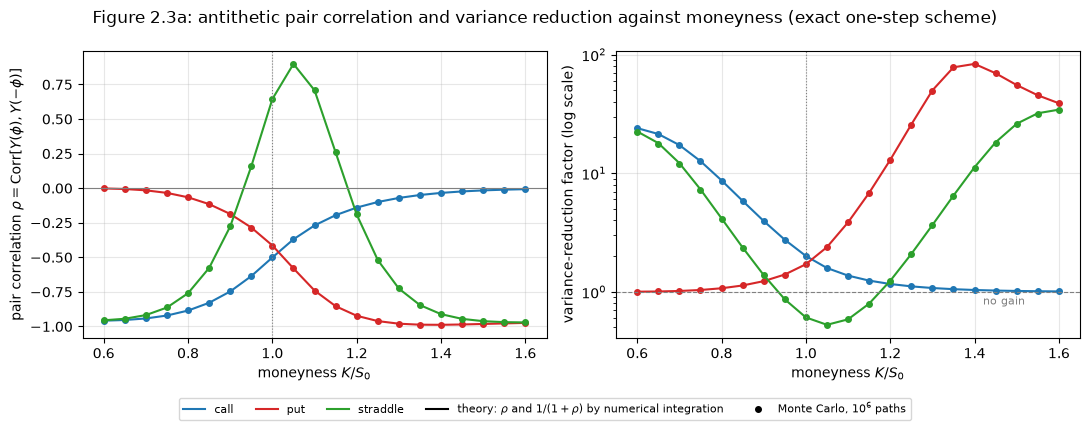

In [31]:
# Figure 2.3a: pair correlation and variance-reduction factor against moneyness, one-step exact scheme.
# One sample of 500,000 antithetic pairs (10^6 paths) is reused for every strike and payoff.
moneyness_2_3 = np.round(np.arange(0.60, 1.601, 0.05), 2)                # K / S0
phi_2_3 = np.random.default_rng(SEED).standard_normal((500_000, 1))
ST_plus_2_3 = exact_paths(S0, r, sigma, T, phi_2_3)[:, -1]
ST_minus_2_3 = exact_paths(S0, r, sigma, T, -phi_2_3)[:, -1]

pair_study_2_3 = {}                                                       # payoff -> measured and theoretical curves
for kind_2_3 in ('call', 'put', 'straddle'):
    curves = {'rho, MC': [], 'factor, MC': [], 'rho, theory': []}
    for strike_ratio in moneyness_2_3:
        strike = strike_ratio * S0
        payoffs_plus = np.exp(-r * T) * payoff_or_straddle(ST_plus_2_3, strike, kind_2_3)
        payoffs_minus = np.exp(-r * T) * payoff_or_straddle(ST_minus_2_3, strike, kind_2_3)
        variance_per_path = np.var(np.concatenate([payoffs_plus, payoffs_minus]), ddof=1)    # Var[Y]
        variance_per_pair = np.var(0.5 * (payoffs_plus + payoffs_minus), ddof=1)           # Var of a pair average
        curves['rho, MC'].append(np.corrcoef(payoffs_plus, payoffs_minus)[0, 1])
        curves['factor, MC'].append(variance_per_path / (2 * variance_per_pair))          # N paths against N/2 pairs
        curves['rho, theory'].append(antithetic_theory(S0, strike, T, r, sigma, kind_2_3)[1])
    pair_study_2_3[kind_2_3] = pd.DataFrame(curves, index=moneyness_2_3)

# Values behind the figure at selected strikes, and the largest gap between simulated and integrated rho
selected_strikes = [0.60, 0.80, 0.90, 0.95, 1.00, 1.05, 1.15, 1.20, 1.40, 1.60]
selected_values = {}
largest_rho_gap = 0.0
for kind_2_3, study in pair_study_2_3.items():
    selected_values[kind_2_3] = study.loc[selected_strikes, ['rho, MC', 'factor, MC']]
    largest_rho_gap = max(largest_rho_gap, (study['rho, MC'] - study['rho, theory']).abs().max())
summary_2_3a = pd.concat(selected_values, axis=1)
colours_2_3 = {'call': 'tab:blue', 'put': 'tab:red', 'straddle': 'tab:green'}
fig, (ax_rho, ax_factor) = plt.subplots(1, 2, figsize=(11, 4.2))
for kind_2_3, study in pair_study_2_3.items():
    colour = colours_2_3[kind_2_3]
    ax_rho.plot(study.index, study['rho, theory'], '-', color=colour, label=kind_2_3)
    ax_rho.plot(study.index, study['rho, MC'], 'o', color=colour, ms=4)
    ax_factor.plot(study.index, 1 / (1 + study['rho, theory']), '-', color=colour, label=kind_2_3)
    ax_factor.plot(study.index, study['factor, MC'], 'o', color=colour, ms=4)
ax_rho.axhline(0, color='grey', lw=0.8)
ax_factor.axhline(1, color='grey', lw=0.8, ls='--')
ax_factor.text(1.42, 0.92, 'no gain', color='grey', fontsize=8, va='top')
for ax in (ax_rho, ax_factor):
    ax.axvline(1.0, color='grey', lw=0.8, ls=':')
    ax.set_xlabel('moneyness $K/S_0$')
    ax.grid(alpha=0.3)
ax_rho.set_ylabel(r'pair correlation $\rho = \mathrm{Corr}[Y(\phi), Y(-\phi)]$')
ax_factor.set_ylabel('variance-reduction factor (log scale)')
ax_factor.set_yscale('log')
# one legend for both panels: colour = payoff, line = theory, dots = Monte Carlo
ax_rho.plot([], [], '-', color='black', label=r'theory: $\rho$ and $1/(1+\rho)$ by numerical integration')
ax_rho.plot([], [], 'o', color='black', ms=4, label='Monte Carlo, $10^6$ paths')
handles, labels = ax_rho.get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=5, fontsize=8)
fig.suptitle('Figure 2.3a: antithetic pair correlation and variance reduction against moneyness '
             '(exact one-step scheme)')
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()


**Reading the results.** All sixteen prices in Table 2.3a lie within about two standard errors of
Black–Scholes; the largest misses, 2.00 to 2.04 standard errors, are the three plain 252-step calls. At equal
cost, antithetic pairing cuts the call's standard error from 0.0468 to 0.0330 (a variance ratio of 2.00) and
the put's from 0.0273 to 0.0210 (1.70), with almost the same ratios under every scheme. Put–call parity gains
far more: in Table 2.3b, pairing cuts the standard error of the residual from about 0.064 to 0.0125–0.0128, a
variance factor of 25.1 for the one-step exact scheme. Across strikes (Figure 2.3a), the gain grows deep in the
money, to 23.8 for the call at $K/S_0 = 0.6$ and 83.3 for the put at $K/S_0 = 1.40$. The at-the-money straddle
goes the other way: its factor is 0.61, so pairing makes it *worse* than plain sampling.
